# mtbs to geoparquet

source: mtbs burned area boundaries (usgs/usfs, public domain), `mtbs_perims_DD.shp`. fetched 2026-11-03, upstream last-modified 2026-11-03, sha256 `5e269e6c…bde0da4`. 30,932 perimeters, 1984-01-26 to 2026-06-05, EPSG:4269.


## notes 

- rows: keep all incident types (wildfire 16,779, prescribed 9,639, other 4,311, wfu 203). filter downstream.
- extent: conus, rows whose perimeter intersects the bbox (-125, 24, -66, 50). 29,518 rows, same as filtering on the `event_id` prefix. cross-border perimeters stay whole.
- crs: 4269 to 4326 for geoparquet-lod.
- columns: shane's 7 (`event_id, incid_name, incid_type, ig_date, year, burnbndac, asmnt_type`) plus geometry and bbox. `ig_date` stays a string since tiles can't carry a date; `year` is an int. a malformed date fails the build.
- invalid geometry: `ST_CollectionExtract(ST_MakeValid(geom), 3)`. 48 invalid, 6 of them duplicated parts. no area change.
- simplify at 1e-6° (~0.1 m). strips the 1 m densified edges (1.87M vertices to 301). geoparquet 335 vs 498 MB, lod 267 vs 357 MB, 29 vs 35 GiB peak.
- zooms 0-11. the auto guess (0-15) ran a laptop out of memory.
- thinning: `drop_smallest`, same as shane. it keeps every perimeter at every zoom; `complete_from` is pinned to 4 anyway.
- tiles carry all 7 fields, same as shane.
- output: `input/historic/mtbs/<YYYYMMDD>/mtbs_perims.parquet`, dated by upstream last-modified. skipped if it exists unless `--overwrite`.
- raw zip mirrored to `.../<YYYYMMDD>/raw/<sha256[:16]>/` after a successful build, never overwritten.
- metadata: source url, last-modified, sha256, retrieved date, mirror key, settings, code versions (`unknown (…)` when they can't be identified).
- dirty builds allowed.
- build on coiled (r8g.4xlarge); peak ~29 GiB, ~5 min.

## ask shane

- makevalid + polygon extract (he had none)
- 0.1 m simplify on the stored geometry

## to confirm

- what "(SS)" in `asmnt_type` means
- what `other` in `incid_type` means. fl has 1,898 of them.

In [52]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

from ocr.duck import duckdb_connect

In [37]:
path = '~/.cache/ocr/mtbs/mtbs_perimeter_data.zip'
fields = ['event_id', 'incid_name', 'incid_type', 'ig_date', 'burnbndac', 'asmnt_type']

In [38]:
shp = f'/vsizip/{Path(path).expanduser()}/mtbs_perims_DD.shp'

con = duckdb_connect()
con.execute(
    f'CREATE TABLE mtbs AS SELECT {", ".join(fields)}, geom FROM ST_Read($shp)', {'shp': shp}
)
mtbs = con.table('mtbs')
mtbs.count('*')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

count_star()BIGINT
30932


In [39]:
df = mtbs.limit(5).df()
df

,event_id,incid_name,incid_type,ig_date,burnbndac,asmnt_type,geom
0,UT4176411148820121004,HELLS HOLLOW,Prescribed Fire,2012-10-04,4756,Extended,bytearray(b'\x01\x03\x00\x00\x00\x01\x00\x00\x...
1,WA4796812059020120908,KLONE PEAK,Wildfire,2012-09-08,1634,Extended,bytearray(b'\x01\x03\x00\x00\x00\x01\x00\x00\x...
2,WA4797012073420120908,BASALT,Wildfire,2012-09-08,1704,Extended,bytearray(b'\x01\x03\x00\x00\x00\x01\x00\x00\x...
3,WA4805112058820120908,PYRAMID,Wildfire,2012-09-08,1962,Extended,bytearray(b'\x01\x03\x00\x00\x00\x01\x00\x00\x...
4,WA4788612026820120908,FIRST CREEK,Wildfire,2012-09-08,1434,Extended,bytearray(b'\x01\x03\x00\x00\x00\x01\x00\x00\x...


In [40]:
# is `event_id` unique
con.sql('SELECT count(DISTINCT event_id) FROM mtbs')

count(DISTINCT event_id)BIGINT
30932


In [41]:
# what do incid_type and asmnt_type contain
con.sql(
    """SELECT
            incid_type,
            COUNT(*) AS n
        FROM mtbs
        GROUP BY ALL;
    """
)

incid_typeVARCHAR,nBIGINT
Prescribed Fire,9639
Wildfire,16779
Other,4311
Wildland Fire Use,203


In [43]:
# incid_type x asmnt_type: Initial vs Extended assessment, (SS) = single scene
con.sql(
    """SELECT incid_type, asmnt_type, count(*) AS n
        FROM mtbs
        GROUP BY ALL
        ORDER BY incid_type, n DESC;
    """
).df()

,incid_type,asmnt_type,n
0,Other,Initial (SS),2783
1,Other,Initial,1445
2,Other,Extended,73
3,Other,Extended (SS),10
4,Prescribed Fire,Initial,6777
5,Prescribed Fire,Initial (SS),2477
6,Prescribed Fire,Extended,367
7,Prescribed Fire,Extended (SS),18
8,Wildfire,Initial,8972
9,Wildfire,Extended,5061


In [44]:
# is ig_date clean
con.sql(
    """DESCRIBE mtbs;
    """
).df()

,column_name,column_type,null,key,default,extra
0,event_id,VARCHAR,YES,None,None,None
1,incid_name,VARCHAR,YES,None,None,None
2,incid_type,VARCHAR,YES,None,None,None
3,ig_date,VARCHAR,YES,None,None,None
4,burnbndac,BIGINT,YES,None,None,None
5,asmnt_type,VARCHAR,YES,None,None,None
6,geom,GEOMETRY('EPSG:4269'),YES,None,None,None


In [45]:
con.sql(
    """SUMMARIZE mtbs;
    """
).df()

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,event_id,VARCHAR,AK5674215793820060522,WY4509511033019880815,31324,NaN,NaN,NaN,NaN,NaN,30932,0.0
1,incid_name,VARCHAR,#1 SEASON FIRE,ZWEYGARDT,17396,NaN,NaN,NaN,NaN,NaN,30932,0.0
2,incid_type,VARCHAR,Other,Wildland Fire Use,3,NaN,NaN,NaN,NaN,NaN,30932,0.0
3,ig_date,VARCHAR,1984-01-26,2026-06-05,9813,NaN,NaN,NaN,NaN,NaN,30932,0.0
4,burnbndac,BIGINT,396,1067970,9239,6919.7600543126855,26192.109467430404,1121,1851,3991,30932,0.0
5,asmnt_type,VARCHAR,Extended,Initial (SS),4,NaN,NaN,NaN,NaN,NaN,30932,0.0
6,geom,GEOMETRY('EPSG:4269'),"POLYGON ((-103.381265 39.264845, -103.382632 3...","MULTIPOLYGON (((-81.070244 25.909403, -81.0699...",32177,NaN,NaN,NaN,NaN,NaN,30932,0.0


In [46]:
# ig_date is VARCHAR, so SUMMARIZE's min/max above are string order; check every value parses as a date
con.sql(
    """SELECT
            count(*) FILTER (WHERE try_cast(ig_date AS DATE) IS NULL) AS unparsable,
            min(try_cast(ig_date AS DATE)) AS first,
            max(try_cast(ig_date AS DATE)) AS last
        FROM mtbs;
    """
)

unparsableBIGINT,firstDATE,lastDATE
0,1984-01-26,2026-06-05


In [47]:
# how much is outside CONUS
con.sql(
    """SELECT
            left(event_id, 2) as prefix,
            count(*) as row_count
        FROM mtbs
        GROUP BY left(event_id, 2)
        ORDER BY row_count DESC;

    """
).df()

,prefix,row_count
0,FL,5639
1,CA,1959
2,TX,1823
3,ID,1623
4,AZ,1435
5,AK,1378
6,MS,1163
7,OR,1091
8,NM,1076
9,AL,1053


In [48]:
# roll the prefixes up: what dropping AK, HI and PR costs
con.sql(
    """SELECT
            left(event_id, 2) IN ('AK', 'HI', 'PR') AS outside_conus,
            count(*) AS n
        FROM mtbs
        GROUP BY ALL;
    """
)

outside_conusBOOLEAN,nBIGINT
False,29518
True,1414


In [49]:
# what are geometries like: type, validity, CRS
con.sql(
    """SELECT
            ST_GeometryType(geom) AS geom_type,
            ST_IsValid(geom) AS valid,
            ST_CRS(geom) AS crs,
            count(*) AS n
        FROM mtbs
        GROUP BY ALL
        ORDER BY n DESC;
    """
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

geom_typeGEOMETRY_TYPE,validBOOLEAN,crsVARCHAR,nBIGINT
POLYGON,True,EPSG:4269,27524
MULTIPOLYGON,True,EPSG:4269,3360
POLYGON,False,EPSG:4269,30
MULTIPOLYGON,False,EPSG:4269,18


In [50]:
# vertex counts: drives file size and how much overviews must simplify
con.sql(
    """SELECT
            min(v) AS min,
            quantile_cont(v, [0.5, 0.9, 0.99]) AS p50_p90_p99,
            max(v) AS max,
            sum(v) AS total
        FROM (SELECT ST_NPoints(geom) AS v FROM mtbs);
    """
)

minUINTEGER,p50_p90_p99DOUBLE[],maxUINTEGER,totalHUGEINT
5,"[338.0, 2275.9000000000015, 11100.799999999974]",2030049,38427545


In [51]:
# the heaviest perimeters, with their size so vertices-per-acre stands out
con.sql(
    """SELECT
            event_id,
            incid_name,
            incid_type,
            burnbndac,
            ST_NPoints(geom) AS vertices,
            ST_NumGeometries(geom) AS parts
        FROM mtbs
        ORDER BY vertices DESC
        LIMIT 10;
    """
).df()

,event_id,incid_name,incid_type,burnbndac,vertices,parts
0,AZ3353710941020240506,EEMS HAZARDOUS FUELS,Prescribed Fire,7359,2030049,1
1,MS3219308934320240405,BIENVILLE CPT 214 RX,Prescribed Fire,935,1866214,1
2,MS3220708936620240319,BIENVILLE C220 RX,Prescribed Fire,1158,1685924,1
3,FL2868508074320230420,MIR 2.2 RX 0420,Prescribed Fire,1510,222310,1
4,CA3966012280920200817,AUGUST COMPLEX,Wildfire,1067970,115910,1
5,CA3850412233720200817,HENNESSEY,Wildfire,314015,114391,1
6,ID4512211538120240909,LOGAN,Wildfire,15859,99442,2
7,AK6657114321520190709,CHALKYITSIK COMPLEX,Wildfire,470271,94852,1
8,WY4489810756920240927,ELK,Wildfire,98842,83568,3
9,OR4472312167920200817,LIONSHEAD,Wildfire,197622,82548,2


In [56]:
# look at one of the outliers
df = con.sql(
    """SELECT
            event_id,
            incid_name,
            ST_AsWKB(geom) AS geom
        FROM mtbs
        WHERE event_id = 'MS3219308934320240405'
        """
).df()

gdf = gpd.GeoDataFrame(df, geometry=gpd.GeoSeries.from_wkb(df['geom'].map(bytes)), crs='EPSG:4269')
gdf

,event_id,incid_name,geom,geometry
0,MS3219308934320240405,BIENVILLE CPT 214 RX,bytearray(b'\x01\x03\x00\x00\x00\x01\x00\x00\x...,"POLYGON ((-89.34836 32.20388, -89.34762 32.203..."


[(-89.34935733016006, -89.34735733016005),
 (32.20288200019713, 32.204882000197124),
 Text(0.5, 1.0, 'vertices (red)')]

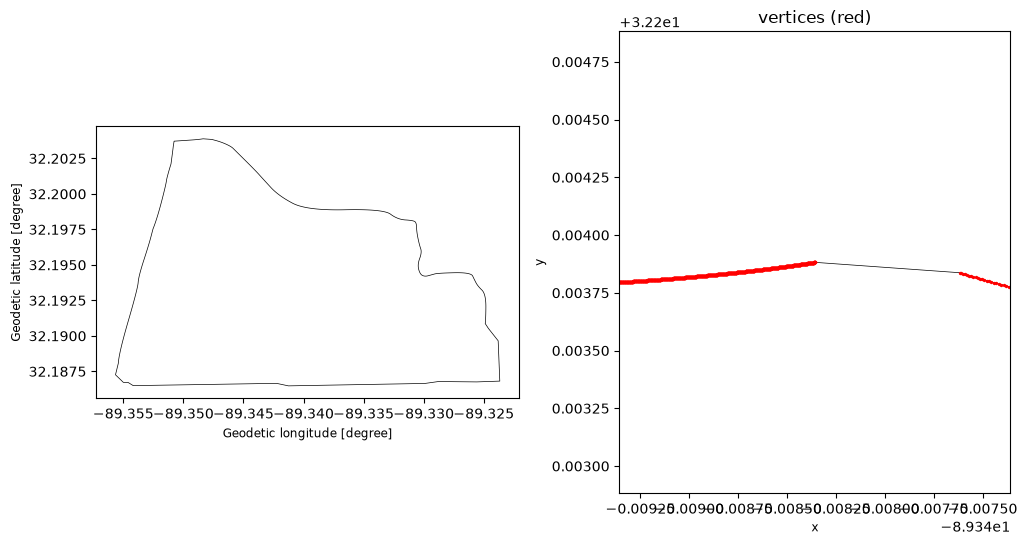

In [57]:
fig, (full, zoom) = plt.subplots(1, 2, figsize=(12, 6))
gdf.plot(ax=full, facecolor='none', edgecolor='k', linewidth=0.5)
gdf.plot(ax=zoom, facecolor='none', edgecolor='k', linewidth=0.5)
gdf.get_coordinates().plot.scatter(x='x', y='y', ax=zoom, s=2, c='r')
x, y = gdf.geometry.iloc[0].exterior.coords[0]
w = 0.001  # ~100 m
zoom.set(xlim=(x - w, x + w), ylim=(y - w, y + w), title='vertices (red)')

In [58]:
# how many vertices survive a ~0.1 m simplification (1e-6 degrees)
con.sql(
    """SELECT
            event_id,
            incid_name,
            ST_NPoints(geom) AS before,
            ST_NPoints(ST_SimplifyPreserveTopology(geom, 1e-6)) AS after
        FROM mtbs
        ORDER BY before DESC
        LIMIT 10;
    """
).df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_id,incid_name,before,after
0,AZ3353710941020240506,EEMS HAZARDOUS FUELS,2030049,4055
1,MS3219308934320240405,BIENVILLE CPT 214 RX,1866214,301
2,MS3220708936620240319,BIENVILLE C220 RX,1685924,625
3,FL2868508074320230420,MIR 2.2 RX 0420,222310,4690
4,CA3966012280920200817,AUGUST COMPLEX,115910,92080
5,CA3850412233720200817,HENNESSEY,114391,85230
6,ID4512211538120240909,LOGAN,99442,15653
7,AK6657114321520190709,CHALKYITSIK COMPLEX,94852,76247
8,WY4489810756920240927,ELK,83568,14792
9,OR4472312167920200817,LIONSHEAD,82548,68693


In [59]:
# what `ST_MakeValid` does to the invalid rows
con.sql(
    """WITH fixed AS (
            SELECT event_id, incid_name, geom, ST_MakeValid(geom) AS fixed
            FROM mtbs
            WHERE NOT ST_IsValid(geom)
        )
        SELECT
            event_id,
            incid_name,
            ST_GeometryType(geom) AS before_type,
            ST_GeometryType(fixed) AS after_type,
            ST_IsValid(fixed) AS now_valid,
            round(100 * (ST_Area(fixed) - ST_Area(geom)) / ST_Area(geom), 3) AS area_change_pct,
            ST_NPoints(fixed)::BIGINT - ST_NPoints(geom)::BIGINT AS vertex_change
        FROM fixed
        ORDER BY abs(area_change_pct) DESC;
    """
).df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_id,incid_name,before_type,after_type,now_valid,area_change_pct,vertex_change
0,CA3983312003820200802,NORTH,MULTIPOLYGON,GEOMETRYCOLLECTION,True,-80.000,-14342
1,UT3766011214320020422,FAIRYLAND 2,MULTIPOLYGON,POLYGON,True,-66.667,-210
2,OR4435711936420060821,THORN CREEK,MULTIPOLYGON,POLYGON,True,-50.000,-833
3,LA3148709317820200228,UNNAMED,MULTIPOLYGON,POLYGON,True,-50.000,-2649
4,AL3425108722020190320,UNNAMED,MULTIPOLYGON,POLYGON,True,-50.000,-3119
5,WY4474311097820160809,MAPLE,MULTIPOLYGON,POLYGON,True,-50.000,-1801
6,FL3097408696320120925,UNNAMED,POLYGON,GEOMETRYCOLLECTION,True,-0.000,0
7,AK6583414299120220620,PACK,POLYGON,GEOMETRYCOLLECTION,True,-0.000,-3
8,UT3793611217320020531,SANFORD,POLYGON,GEOMETRYCOLLECTION,True,-0.000,-3
9,TX3564410163220020418,SHORTCREEK,MULTIPOLYGON,GEOMETRYCOLLECTION,True,0.000,-2


In [60]:
# are the six "area-losing" multipolygons duplicated parts?
con.sql(
    """WITH bad AS (
            SELECT event_id, incid_name, geom
            FROM mtbs
            WHERE NOT ST_IsValid(geom) AND ST_GeometryType(geom) = 'MULTIPOLYGON'
        ),
        parts AS (
            SELECT event_id, unnest(ST_Dump(geom)).geom AS part FROM bad
        )
        SELECT
            b.event_id,
            b.incid_name,
            ST_NumGeometries(b.geom) AS parts,
            (SELECT count(DISTINCT ST_AsHEXWKB(p.part)) FROM parts p WHERE p.event_id = b.event_id) AS distinct_parts,
            round(ST_Area(b.geom) / ST_Area(ST_MakeValid(b.geom)), 3) AS area_ratio
        FROM bad b
        ORDER BY area_ratio DESC;
    """
).df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_id,incid_name,parts,distinct_parts,area_ratio
0,CA3983312003820200802,NORTH,5,2,5.0
1,UT3766011214320020422,FAIRYLAND 2,3,1,3.0
2,OR4435711936420060821,THORN CREEK,2,1,2.0
3,WY4474311097820160809,MAPLE,2,1,2.0
4,AL3425108722020190320,UNNAMED,2,1,2.0
5,LA3148709317820200228,UNNAMED,2,1,2.0
6,FL3060308419720110404,UNNAMED,3,3,1.0
7,TX3564410163220020418,SHORTCREEK,7,7,1.0
8,AK6321915689520040715,HURST,2,2,1.0
9,FL2861808063920060121,RX BURN 5.2C,2,2,1.0


the parts are exact duplicates. for instance, 
- fairyland 2 has 3 parts but only 1 distinct, and the area ratio is exactly 3.0.
- north has 5 parts, 2 distinct, and a ratio of 5.0
- the other 12 invalid multipolygons have all-distinct parts and a ratio of 1.0

so `ST_MakeValid` doesn't shrink any fire; it removes the double counting

In [61]:
# does ST_CollectionExtract keep all the area?

con.sql(
    """WITH fixed AS (
            SELECT event_id, ST_MakeValid(geom) AS valid
            FROM mtbs
            WHERE NOT ST_IsValid(geom)
        ),
        extracted AS (
            SELECT *, ST_CollectionExtract(valid, 3) AS polys FROM fixed
        )
        SELECT
            ST_GeometryType(valid) AS valid_type,
            ST_GeometryType(polys) AS extracted_type,
            count(*) AS n,
            max(abs(ST_Area(polys) - ST_Area(valid)) / ST_Area(valid)) AS max_rel_area_diff,
            bool_and(ST_IsValid(polys)) AS all_valid
        FROM extracted
        GROUP BY ALL
        ORDER BY n DESC;
    """
).df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,valid_type,extracted_type,n,max_rel_area_diff,all_valid
0,GEOMETRYCOLLECTION,MULTIPOLYGON,29,0.0,True
1,POLYGON,POLYGON,14,0.0,True
2,MULTIPOLYGON,MULTIPOLYGON,5,0.0,True


no area lost: all 48 rows come out valid with a relative area difference of 0.0. the 29 GEOMETRYCOLLECTIONs become MULTIPOLYGON

In [62]:
# incident types by state

con.sql(
    """PIVOT (SELECT left(event_id, 2) AS state, incid_type FROM mtbs)
        ON incid_type USING count(*)
        ORDER BY state;
    """
).df()

,state,Other,Prescribed Fire,Wildfire,Wildland Fire Use
0,AK,9,31,1272,66
1,AL,24,912,117,0
2,AR,103,839,99,1
3,AZ,147,313,952,23
4,CA,63,125,1744,27
5,CO,23,26,381,6
6,DE,4,0,1,0
7,FL,1898,2849,884,8
8,GA,246,332,121,0
9,HI,2,0,27,0
